# M5 Forecasting — Part 1 · Statistical models
## Notebook 01 · EDA

**Owner:** Ruihang 



### The map of this notebook

| # | Question I want to answer | for ARIMA / SARIMA | for ML / DL  |
|---|---|---|---|
| 1 | Load data with clear names | — | Same variable names across our notebooks |
| 2 | How do I turn 30,490 rows into time series? | ARIMA needs **one series = one column of numbers over time** | Same aggregates can become features |
| 3 | Trend: is everybody growing the same way? | Decide differencing (`d`) per level | Trend / level features |
| 4 | Seasonality: week and year | Seasonal period `s = 7`, Fourier terms for the year | Day-of-week, month features |
| 5 | Decomposition: how big is each part? | How much of the signal ARIMA must explain | — |
| 6 | Calendar effects: holidays & SNAP | Dummy variables → **SARIMAX** | Event / SNAP features |
| 7 | Prices & revenue | Which series weigh most in the M5 score | Price features |
| 8 | Intermittency of single products | Why we model at aggregate level | Loss function choice (Tweedie / Poisson) |
| 9 | Outliers & structural breaks | What to clean before fitting | Same cleaning |
| 10 | Summary + export of the series for notebook 02 | — | — |

### Variable naming convention

| Prefix | Meaning | Example |
|---|---|---|
| `df_..._raw` / `df_calendar` / `df_prices` | Original csv, never modified | `df_sales_wide` |
| `ts_...` | **One** time series (pandas Series, index = date) | `ts_total` |
| `df_ts_...` | **Several** time series side by side (DataFrame, index = date, one column per group) | `df_ts_store` |
| `tbl_...` | A small summary table to read with my eyes | `tbl_yearly_growth` |

## 1 · Setup and loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import TwoSlopeNorm

DATA_DIR = Path("m5-forecasting-accuracy")      # the Kaggle folder sits next to this notebook
OUT_DIR = Path("data_processed")                # I save my cleaned series here for notebook 02
OUT_DIR.mkdir(exist_ok=True)

# Same colours as notebook 00 -> all our charts look like one project
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, INK, INK2 = "#9a9893", "#0b0b0b", "#52514e"
STATE_COLORS = {"CA": BLUE, "TX": ORANGE, "WI": AQUA}
CAT_COLORS = {"FOODS": BLUE, "HOBBIES": ORANGE, "HOUSEHOLD": AQUA}

plt.rcParams.update({
    "figure.figsize": (12, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c9c8c3", "axes.labelcolor": INK2, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.grid": True, "axes.axisbelow": True,
    "grid.color": "#ecebe7", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 1.6,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

def k_format(ax):
    # small helper: show 30000 as "30k" (and 1500 as "1.5k") on the y axis, easier to read
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1000:.0f}k" if v % 1000 == 0 else f"{v/1000:.1f}k"))

In [2]:
# --- Step 1: read the 3 csv files I need ---
# The day columns are small integers (max ~700), so I store them as int16 instead of int64.
# This makes the sales table 4x lighter in memory.
sales_header = pd.read_csv(DATA_DIR / "sales_train_evaluation.csv", nrows=0).columns
d_cols = [c for c in sales_header if c.startswith("d_")]      # ['d_1', 'd_2', ..., 'd_1941']

df_sales_wide = pd.read_csv(DATA_DIR / "sales_train_evaluation.csv",
                            dtype={c: "int16" for c in d_cols})
df_calendar = pd.read_csv(DATA_DIR / "calendar.csv", parse_dates=["date"])
df_prices = pd.read_csv(DATA_DIR / "sell_prices.csv",
                        dtype={"store_id": "category", "item_id": "category",
                               "wm_yr_wk": "int16", "sell_price": "float32"})

# --- Step 2: quick sanity check, I always print the shapes first ---
print("df_sales_wide :", df_sales_wide.shape, "-> one row per item x store, one column per day")
print("df_calendar   :", df_calendar.shape, "-> one row per day (incl. 28 future days)")
print("df_prices     :", df_prices.shape, "-> one row per item x store x week")

df_sales_wide : (30490, 1947) -> one row per item x store, one column per day
df_calendar   : (1969, 14) -> one row per day (incl. 28 future days)
df_prices     : (6841121, 4) -> one row per item x store x week


In [3]:
# --- Step 3: the real dates of my 1941 sales days ---
# df_calendar has 1969 rows, but sales are only known for the first 1941 days.
# I keep the dates in one variable because I will use them as index everywhere.
sales_dates = pd.DatetimeIndex(df_calendar["date"].iloc[:len(d_cols)])
print("First day:", sales_dates[0].date(), "| Last day:", sales_dates[-1].date(), "| Number of days:", len(sales_dates))

# Our own test set = the last 28 days (we know the true answers for them)
TEST_START = sales_dates[-28]
print("Test set starts on:", TEST_START.date())

First day: 2011-01-29 | Last day: 2016-05-22 | Number of days: 1941
Test set starts on: 2016-04-25


## 2 · From a big table to time series

Right now `df_sales_wide` looks like a spreadsheet where every **row** is one product in one store and every **column** is a day. ARIMA cannot read that. ARIMA wants **one list of numbers ordered in time**, like:

| date | units |
|---|---|
| 2011-01-29 | 32,631 |
| 2011-01-30 | 31,749 |
| … | … |

So I write a small function that **adds up all rows belonging to the same group** (e.g. same store) and **turns the table into a long format from wide foramt** so that time goes downward.

In [4]:
def make_daily_series(group_cols):
    # Turn the wide sales table into time series, one column per group.
    # group_cols: e.g. "state_id", or ["store_id", "cat_id"]

    # Step 1: add up every product inside each group, day by day
    grouped = df_sales_wide.groupby(group_cols)[d_cols].sum()

    # Step 2: flip the table -> rows = days, columns = groups
    daily = grouped.T

    # Step 3: replace 'd_1', 'd_2'... by real dates
    daily.index = sales_dates

    # Step 4: if I grouped by 2 columns, the column names are tuples like ('CA_1', 'FOODS')
    #         -> I glue them into one readable name 'CA_1_FOODS'
    if isinstance(daily.columns, pd.MultiIndex):
        daily.columns = ["_".join(col) for col in daily.columns]

    return daily.astype("int64")


# Level 1: the grand total (just one series)
ts_total = df_sales_wide[d_cols].sum().astype("int64")
ts_total.index = sales_dates
ts_total.name = "total"

# Levels 2-5 and 8: several series each
df_ts_state = make_daily_series("state_id")
df_ts_store = make_daily_series("store_id")
df_ts_cat = make_daily_series("cat_id")
df_ts_dept = make_daily_series("dept_id")
df_ts_state_cat = make_daily_series(["state_id", "cat_id"])

print("ts_total        :", ts_total.shape)
for name, df in [("df_ts_state", df_ts_state), ("df_ts_store", df_ts_store), ("df_ts_cat", df_ts_cat),
                 ("df_ts_dept", df_ts_dept), ("df_ts_state_cat", df_ts_state_cat)]:
    print(f"{name:16s}:", df.shape, "->", list(df.columns)[:5], "...")

df_ts_store.head()

ts_total        : (1941,)
df_ts_state     : (1941, 3) -> ['CA', 'TX', 'WI'] ...
df_ts_store     : (1941, 10) -> ['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1'] ...
df_ts_cat       : (1941, 3) -> ['FOODS', 'HOBBIES', 'HOUSEHOLD'] ...
df_ts_dept      : (1941, 7) -> ['FOODS_1', 'FOODS_2', 'FOODS_3', 'HOBBIES_1', 'HOBBIES_2'] ...
df_ts_state_cat : (1941, 9) -> ['CA_FOODS', 'CA_HOBBIES', 'CA_HOUSEHOLD', 'TX_FOODS', 'TX_HOBBIES'] ...


store_id,CA_1,CA_2,CA_3,CA_4,TX_1,TX_2,TX_3,WI_1,WI_2,WI_3
date,,,,,,,,,,
2011-01-29,4337,3494,4739,1625,2556,3852,3030,2704,2256,4038
2011-01-30,4155,3046,4827,1777,2687,3937,3006,2194,1922,4198
2011-01-31,2816,2121,3785,1386,1822,2731,2225,1562,2018,3317
2011-02-01,3051,2324,4232,1440,2258,2954,2169,1251,2522,3211
2011-02-02,2630,1942,3817,1536,1694,2492,1726,2,1175,2132


**Quick check that my function is right:** if I add up the 3 states, I must get the total back exactly. Same for stores and categories.

In [5]:
print("states add up to total     :", (df_ts_state.sum(axis=1) == ts_total).all())
print("stores add up to total     :", (df_ts_store.sum(axis=1) == ts_total).all())
print("categories add up to total :", (df_ts_cat.sum(axis=1) == ts_total).all())

states add up to total     : True
stores add up to total     : True
categories add up to total : True


Sales can be **added up** along the product tree (item → dept → category → total) and the geography tree (store → state → total)."

In [33]:
levels = [
    ("1  Total", []), ("2  State", ["state_id"]), ("3  Store", ["store_id"]),
    ("4  Category", ["cat_id"]), ("5  Department", ["dept_id"]),
    ("6  State × Category", ["state_id", "cat_id"]), ("7  State × Department", ["state_id", "dept_id"]),
    ("8  Store × Category", ["store_id", "cat_id"]), ("9  Store × Department", ["store_id", "dept_id"]),
    ("10 Item", ["item_id"]), ("11 Item × State", ["item_id", "state_id"]), ("12 Item × Store", ["item_id", "store_id"]),
]
X = df_sales_wide[d_cols].to_numpy()
rows = []
for name, keys in levels:
    if keys:
        agg = df_sales_wide.groupby(keys)[d_cols].sum().to_numpy()
    else:
        agg = X.sum(axis=0, keepdims=True)
    rows.append({"level": name, "n_series": agg.shape[0],
                 "avg units / day / series": agg.mean().round(1),
                 "% of days with 0 df_sales_wide": (agg == 0).mean() * 100})
hier = pd.DataFrame(rows).set_index("level")
print("Total series across the 12 levels:", hier["n_series"].sum())
hier.round(1)

Total series across the 12 levels: 42840


,n_series,avg units / day / series,% of days with 0 df_sales_wide
level,,,
1 Total,1,34480.8,0.0
2 State,3,11493.6,0.0
3 Store,10,3448.1,0.1
4 Category,3,11493.6,0.2
5 Department,7,4925.8,0.2
6 State × Category,9,3831.2,0.2
7 State × Department,21,1641.9,0.2
8 Store × Category,30,1149.4,0.2
9 Store × Department,70,492.6,0.3


- At the **bottom** (level 12: one product in one store) about **68 % of all days are zeros**. Such a series looks like 0 0 1 0 0 0 2 0 … — this is called **intermittent demand**. ARIMA assumes a continuous, roughly bell-shaped signal, so it fits these badly (it predicts 0.3 units, or negative units).
- At the **top** (levels 1–9) zeros practically disappear (the few remaining are Christmas closures). The series are smooth, trended and seasonal — **exactly what ARIMA/SARIMA were designed for.**

⇒ This is the data-driven argument for running ARIMA / SARIMA on **aggregate levels** (total, state, store, category…), not on 30,490 individual items.

## 3 · Trend 

smooth the series with a **28-day moving average** (each point = average of the 28 days around it)

In [6]:
# I use the yearly AVERAGE units per day (not the sum), because 2011 and 2016 are not full years.
# Average per day is fair to compare between a full and a partial year.
tbl_yearly = pd.DataFrame({"Total": ts_total})
tbl_yearly = tbl_yearly.join(df_ts_state).join(df_ts_cat)
tbl_yearly = tbl_yearly.groupby(tbl_yearly.index.year).mean().round(0).astype(int)
tbl_yearly.index.name = "year"
tbl_yearly

,Total,CA,TX,WI,FOODS,HOBBIES,HOUSEHOLD
year,,,,,,,
2011,26281,11703,8045,6533,18572,2787,4922
2012,32956,14395,9868,8693,23662,2623,6671
2013,35988,15709,10351,9928,24634,3310,8044
2014,35862,15750,10064,10048,24645,3243,7974
2015,37810,16348,10572,10890,24695,3809,9306
2016,41835,17725,11157,12953,27989,3913,9933


In [7]:
# Growth in % compared with the previous year -> easier to compare than raw numbers
tbl_yearly_growth = (tbl_yearly.pct_change() * 100).round(1)
tbl_yearly_growth = tbl_yearly_growth.drop(index=2011)    # 2011 has no previous year
print("Year-over-year growth of average daily units (%)")
print("(careful: 2016 only has Jan-May, and Jan is a weak month, see section 4)")
tbl_yearly_growth

Year-over-year growth of average daily units (%)
(careful: 2016 only has Jan-May, and Jan is a weak month, see section 4)


,Total,CA,TX,WI,FOODS,HOBBIES,HOUSEHOLD
year,,,,,,,
2012,25.4,23.0,22.7,33.1,27.4,-5.9,35.5
2013,9.2,9.1,4.9,14.2,4.1,26.2,20.6
2014,-0.4,0.3,-2.8,1.2,0.0,-2.0,-0.9
2015,5.4,3.8,5.0,8.4,0.2,17.5,16.7
2016,10.6,8.4,5.5,18.9,13.3,2.7,6.7


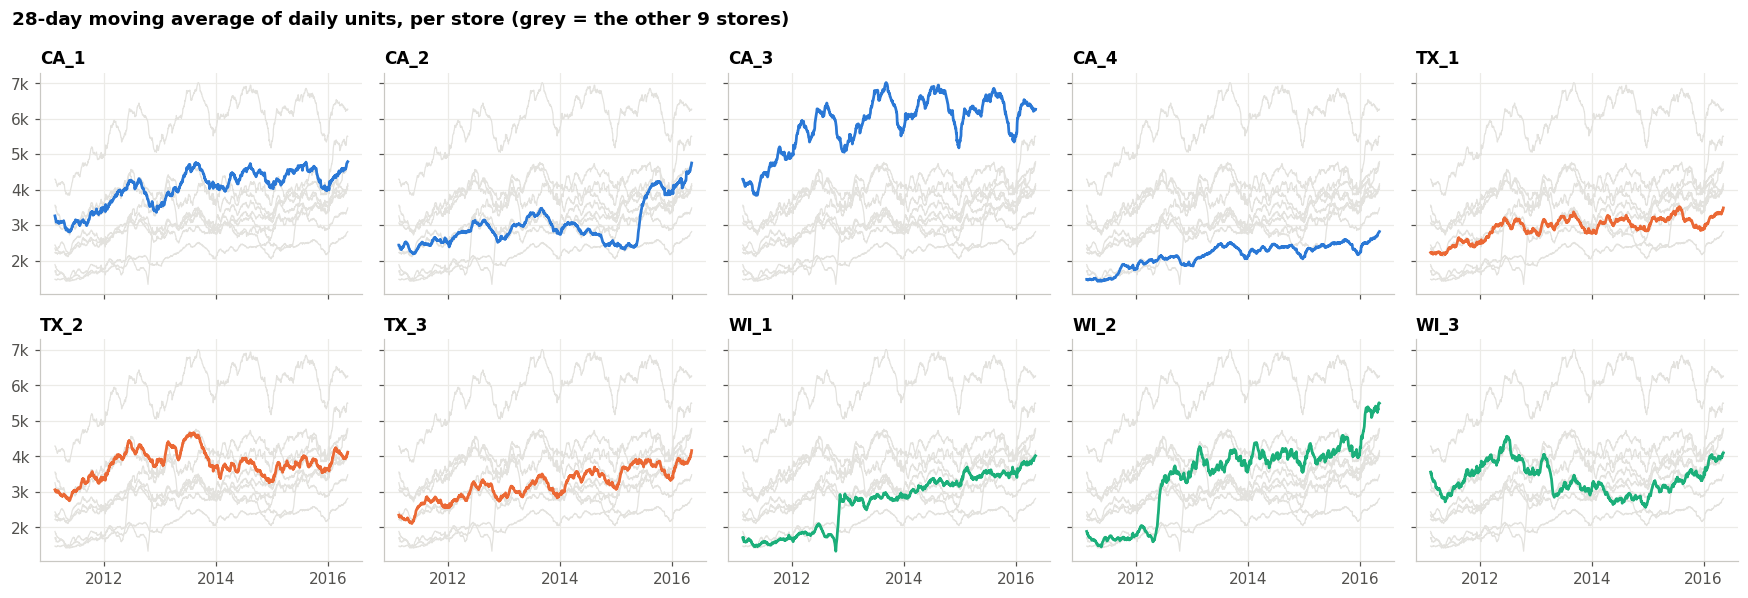

In [8]:
# Small multiples: one small chart per store, all with the SAME y axis so I can compare levels.
fig, axes = plt.subplots(2, 5, figsize=(16, 5.5), sharex=True, sharey=True)
store_order = ["CA_1", "CA_2", "CA_3", "CA_4", "TX_1", "TX_2", "TX_3", "WI_1", "WI_2", "WI_3"]

for ax, store in zip(axes.flatten(), store_order):
    state = store[:2]
    smooth = df_ts_store[store].rolling(28, center=True).mean()
    # every other store in light grey as background -> context
    for other in store_order:
        ax.plot(df_ts_store.index, df_ts_store[other].rolling(28, center=True).mean(), color="#e3e2de", lw=0.8)
    ax.plot(smooth.index, smooth, color=STATE_COLORS[state], lw=1.8)
    ax.set_title(store, fontsize=11)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    k_format(ax)

fig.suptitle("28-day moving average of daily units, per store (grey = the other 9 stores)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**What I see**

- **Very different sizes:** CA_3 is by far the biggest store (5,900 units/day), CA_4 the smallest (2,200)
- **Sudden jumps that stay — "structural breaks":**
  - **WI_1** jumps by about +60 % at the end of 2012 and never comes back.
  - **WI_2** jumps in mid-2012, and again at the start of 2016.
  - **CA_2** slowly declines in 2014–2015, then suddenly jumps up in mid-2015.
  - **WI_3** and **TX_2** drift down for 2–3 years after 2013.
- These look like real business events, not noise. We don't know the cause, the data has no column for it.

**Why it matters for ARIMA:** a store-level ARIMA fitted on 5 years will "average" the before and after periods. For stores with a break, I will either 
  - **(a)** fit only on the data after the last break, or 
  - **(b)** add a step dummy (0 before / 1 after). The **total** and **state** series are much less affected because the breaks partly cancel out

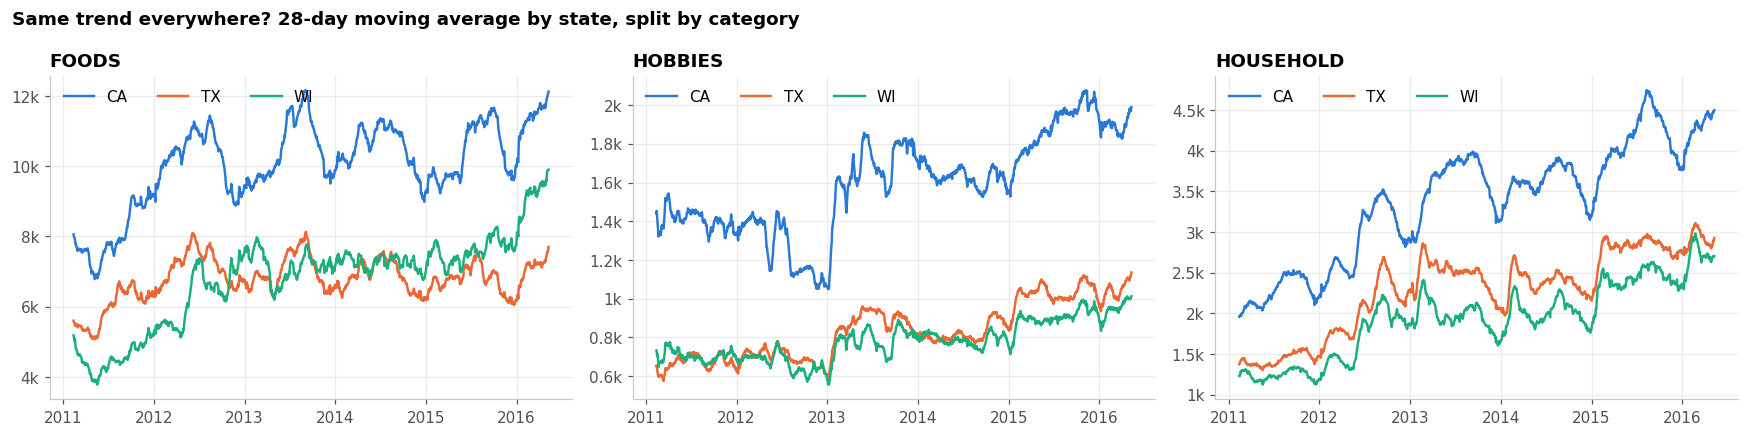

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=False)
for ax, cat in zip(axes, ["FOODS", "HOBBIES", "HOUSEHOLD"]):
    for state in ["CA", "TX", "WI"]:
        smooth = df_ts_state_cat[f"{state}_{cat}"].rolling(28, center=True).mean()
        ax.plot(smooth.index, smooth, color=STATE_COLORS[state], label=state)
    ax.set_title(cat)
    k_format(ax)
    ax.legend(loc="upper left", ncol=3)
fig.suptitle("Same trend everywhere? 28-day moving average by state, split by category",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**What I see**

- **FOODS:** CA is always on top. WI starts as the smallest, catches up with TX in 2012–2013, and clearly overtakes it in 2016.
- **HOBBIES:** CA drops sharply at the end of 2012 and then jumps up at the start of 2013. This looks like a change in the product range (assortment), not in customer behaviour. TX and WI move together.
- **HOUSEHOLD:** the cleanest growth of the three categories, in all states.
- **Year-over-year table:** +25 % in 2012 (partly because many products were launched in 2011–2012, see notebook 00), then ~0 % in 2014, then growth again in 2015–2016.

**Why it matters for ARIMA:** the trend is not a straight line (fast growth → flat → growth again). A model with a fixed linear trend would be wrong. Differencing (`d = 1`) is the flexible option

## 4 · Seasonality: for the week and the year

"Seasonality" = a pattern that **repeats at a fixed rhythm**. In retail there are usually two rhythms: the **week** (people shop on weekends) and the **year** (seasons, holidays).

To measure it in a fair way I use an **index**: for each group I divide by its own average. So `1.20` means "20 % above a normal day for this group". This way a big store and a small store can be compared on the same scale.

Before computing anything I remove the 5 Christmas days, otherwise those near-zero days pull the averages down.

In [10]:
# Christmas = the stores are closed, sales ~ 0. I mark these days once and reuse the mask.
is_christmas = (sales_dates.month == 12) & (sales_dates.day == 25)
print("Christmas days found:", list(sales_dates[is_christmas].date))

def weekday_index(df_ts):
    # Average sales for each weekday, divided by the overall average of that column.
    df_ok = df_ts[~is_christmas]
    by_weekday = df_ok.groupby(df_ok.index.dayofweek).mean()     # 0 = Monday ... 6 = Sunday
    index = by_weekday / df_ok.mean()
    index.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    return index.T                                               # rows = groups, columns = weekdays

tbl_weekday_store = weekday_index(df_ts_store).round(2)
tbl_weekday_cat = weekday_index(df_ts_state_cat).round(2)
tbl_weekday_store

Christmas days found: [datetime.date(2011, 12, 25), datetime.date(2012, 12, 25), datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25)]


,Mon,Tue,Wed,Thu,Fri,Sat,Sun
store_id,,,,,,,
CA_1,0.96,0.85,0.83,0.84,1.00,1.26,1.28
CA_2,0.88,0.82,0.82,0.84,1.01,1.34,1.28
CA_3,1.00,0.92,0.89,0.88,0.95,1.15,1.21
CA_4,1.01,0.93,0.91,0.91,0.98,1.11,1.15
TX_1,0.96,0.88,0.88,0.88,0.96,1.18,1.25
TX_2,0.97,0.87,0.87,0.88,0.99,1.19,1.23
TX_3,1.00,0.91,0.89,0.89,0.98,1.15,1.19
WI_1,0.86,0.83,0.86,0.87,1.06,1.35,1.17
WI_2,0.94,0.92,0.94,0.94,1.04,1.16,1.06


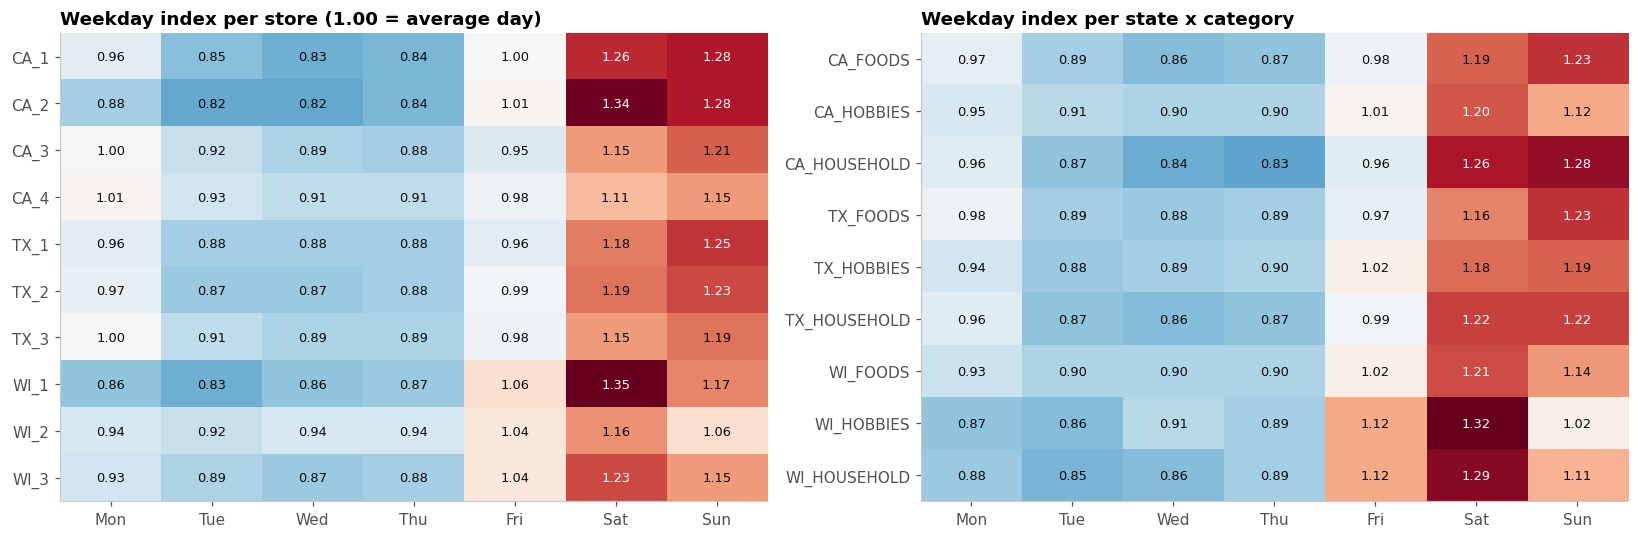

In [11]:
def heatmap_table(tbl, title, ax, center=1.0, fmt="{:.2f}"):
    # Heatmap with the number written in each cell.
    # Blue = below average, red = above average, white = exactly the center (1.00 or 0%).
    # I make the colour scale symmetric around the center, otherwise a small +3 could look as red as a big +30.
    spread = np.nanmax(np.abs(tbl.values - center))
    norm = TwoSlopeNorm(vmin=center - spread, vcenter=center, vmax=center + spread)
    ax.imshow(tbl.values, cmap="RdBu_r", norm=norm, aspect="auto")
    ax.set_xticks(range(tbl.shape[1])); ax.set_xticklabels(tbl.columns)
    ax.set_yticks(range(tbl.shape[0])); ax.set_yticklabels(tbl.index)
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            value = tbl.values[i, j]
            # dark cells -> white text, light cells -> black text
            text_color = "white" if abs(value - center) > 0.6 * spread else INK
            ax.text(j, i, fmt.format(value), ha="center", va="center", fontsize=8.5, color=text_color)
    ax.set_title(title); ax.grid(False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
heatmap_table(tbl_weekday_store, "Weekday index per store (1.00 = average day)", axes[0])
heatmap_table(tbl_weekday_cat, "Weekday index per state x category", axes[1])
plt.tight_layout(); plt.show()

**What I see**

- **Every series has the weekend peak**, but the size differs a lot. On CA_1 / CA_2 the weekend is about +26 % to +34 %; on WI_2 it is only +16 % on Saturday and +6 % on Sunday.
- **Wisconsin is different:** in WI, **Saturday > Sunday** (e.g. WI_1: Sat 1.35, Sun 1.17). In CA and TX it's the opposite, Sunday ≥ Saturday. (The headsortails R kernel found the same "WI Sunday dip".)
- In WI, HOBBIES and HOUSEHOLD also get a **Friday boost** (1.12).
- Tue–Thu are the quiet days everywhere (~0.82–0.94).

**ARIMA:** the weekly shape is **not the same for every store**. So one SARIMA per series (each with its own seasonal coefficients) makes more sense? than one shared weekly profile

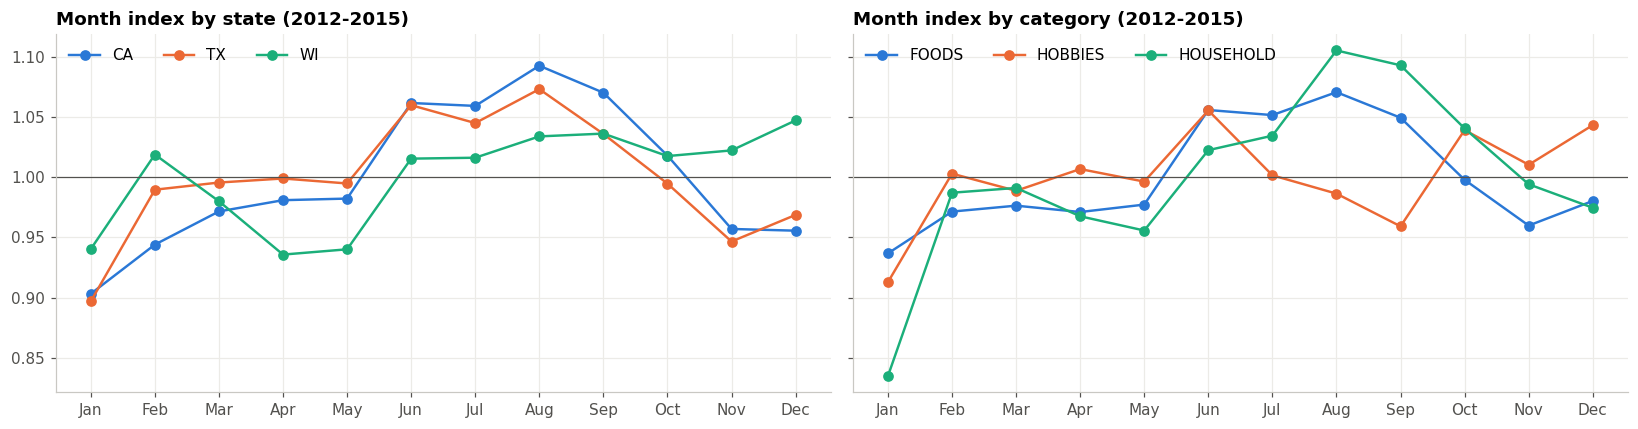

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
state_id,,,,,,,,,,,,
CA,0.90,0.94,0.97,0.98,0.98,1.06,1.06,1.09,1.07,1.02,0.96,0.96
TX,0.90,0.99,1.00,1.00,0.99,1.06,1.04,1.07,1.04,0.99,0.95,0.97
WI,0.94,1.02,0.98,0.94,0.94,1.02,1.02,1.03,1.04,1.02,1.02,1.05


In [12]:
def month_index(df_ts):
    # Same idea as weekday_index, but for months.
    # I only keep full years 2012-2015, otherwise 2011 (starts end of Jan) and 2016 (stops in May) bias it.
    df_ok = df_ts[~is_christmas]
    df_ok = df_ok[(df_ok.index.year >= 2012) & (df_ok.index.year <= 2015)]
    by_month = df_ok.groupby(df_ok.index.month).mean()
    return by_month / df_ok.mean()

tbl_month_state = month_index(df_ts_state)
tbl_month_cat = month_index(df_ts_cat)
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for col in tbl_month_state.columns:
    axes[0].plot(month_names, tbl_month_state[col], color=STATE_COLORS[col], marker="o", label=col)
for col in tbl_month_cat.columns:
    axes[1].plot(month_names, tbl_month_cat[col], color=CAT_COLORS[col], marker="o", label=col)
for ax, t in zip(axes, ["Month index by state (2012-2015)", "Month index by category (2012-2015)"]):
    ax.axhline(1, color=INK2, lw=0.8); ax.set_title(t); ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

tbl_month_state.T.round(2).set_axis(month_names, axis=1)

**What I see**

- **January is the weakest month everywhere** (CA and TX ≈ 0.90; HOUSEHOLD even 0.84) 
- **CA and TX** peak in **summer** (Jun–Sep, ≈ +5 % to +9 %).
- **WI** has an almost flat summer, but a stronger **December** (1.05) and **February** (1.02) than the others. Its year looks different, like its week.
- **HOUSEHOLD** has the biggest yearly swing (0.84 in Jan → 1.11 in Aug).

**Why it matters for ARIMA:** the yearly pattern is real but smaller than the weekly one, and it varies by state and category. 

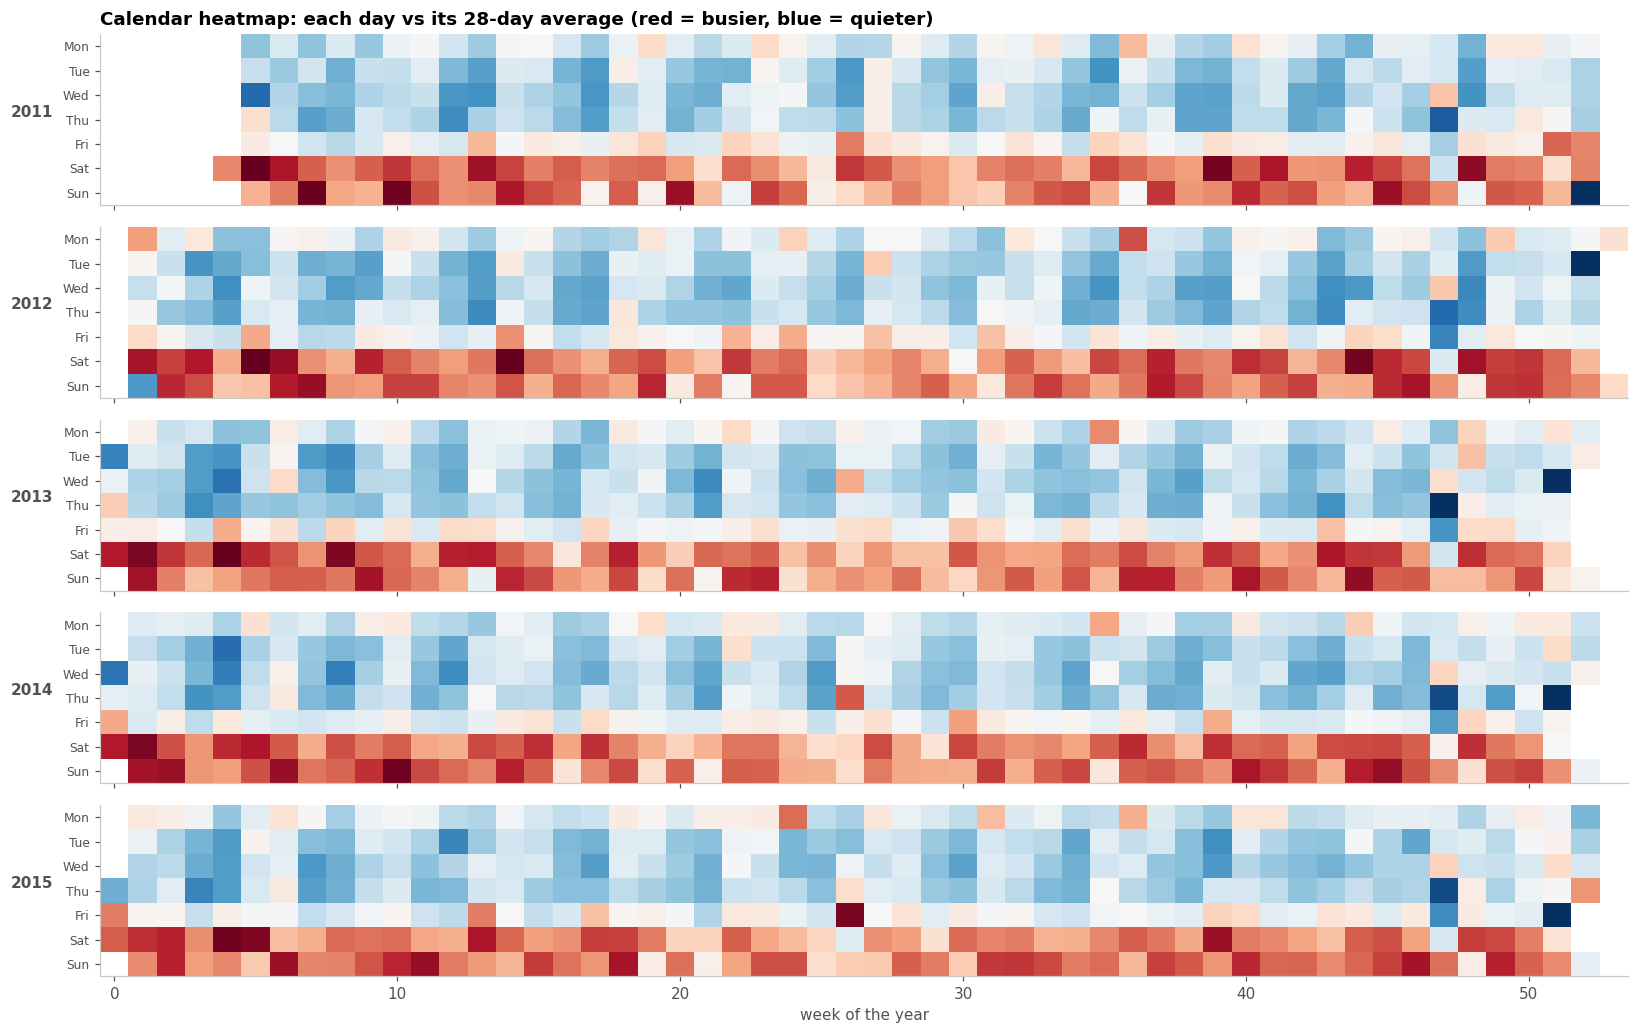

In [13]:
# Last seasonality view: the calendar heatmap of the total.
# Each cell = one day. Rows = weekday, columns = week of the year. One panel per year.
# The colour = sales of that day divided by the 28-day moving average around it
# (so the long-term trend is removed and only the "how special is this day" is left).
ratio = ts_total / ts_total.rolling(28, center=True, min_periods=7).mean()

fig, axes = plt.subplots(5, 1, figsize=(15, 9.5), sharex=True)
for ax, year in zip(axes, [2011, 2012, 2013, 2014, 2015]):
    r = ratio[ratio.index.year == year]
    grid = np.full((7, 54), np.nan)
    for day, value in r.items():
        week = int(day.strftime("%U"))       # week number in the year
        grid[day.dayofweek, week] = value
    ax.imshow(grid, cmap="RdBu_r", norm=TwoSlopeNorm(vmin=0.6, vcenter=1, vmax=1.4), aspect="auto")
    ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], fontsize=8)
    ax.set_ylabel(year, rotation=0, labelpad=20, fontweight="bold"); ax.grid(False)
axes[-1].set_xlabel("week of the year")
axes[0].set_title("Calendar heatmap: each day vs its 28-day average (red = busier, blue = quieter)")
plt.tight_layout(); plt.show()

**How to read it:** every small square is one day. Red = busier than the days around it, blue = quieter.

- The **two red rows (Sat, Sun) every single week** are the weekly seasonality. It is so regular that it's almost boring, and that is exactly what SARIMA is good at.
- **Week 47, Thursday** is dark blue every year: **Thanksgiving**. The **Wednesday just before** is red (people shop the day before), and the Friday after is also below normal.
- The end of each year shows **Christmas** (dark blue) and a red **31 December**.
- The rest is a light patchwork: random day-to-day noise.

**Why it matters:** the special days are few, they are known in advance, and they come back every year. That is the perfect use case for **dummy variables** (0/1 columns) in SARIMAX, rather than letting ARIMA treat them as random shocks.

## 5 · Decomposition 


`sales = trend (slow direction) + weekly pattern + yearly pattern + remainder (the noise nobody can explain)`

 **MSTL** (*Multiple Seasonal-Trend decomposition using Loess*). "Multiple" because it can peel off *two* seasonal rhythms (7 days and 365 days) at the same time, which the classic `seasonal_decompose` cannot do well.

Before that I replace the 5 Christmas days, otherwise the method thinks something crazy happens every 25 December. I use the simplest honest fix: the average of the same weekday one week before and one week after.

In [14]:
def fix_christmas(ts):
    # Replace each Christmas value by the mean of (same weekday -7 days, +7 days).
    ts_fixed = ts.astype(float).copy()
    for day in ts.index[(ts.index.month == 12) & (ts.index.day == 25)]:
        before = ts.get(day - pd.Timedelta(days=7))
        after = ts.get(day + pd.Timedelta(days=7))
        ts_fixed[day] = np.mean([before, after])
    return ts_fixed

ts_total_clean = fix_christmas(ts_total)
print(pd.DataFrame({"raw": ts_total[is_christmas], "fixed": ts_total_clean[is_christmas].round(0)}))

            raw    fixed
date                    
2011-12-25   13  26947.0
2012-12-25   11  27170.0
2013-12-25   20  27768.0
2014-12-25   20  29410.0
2015-12-25   14  33704.0


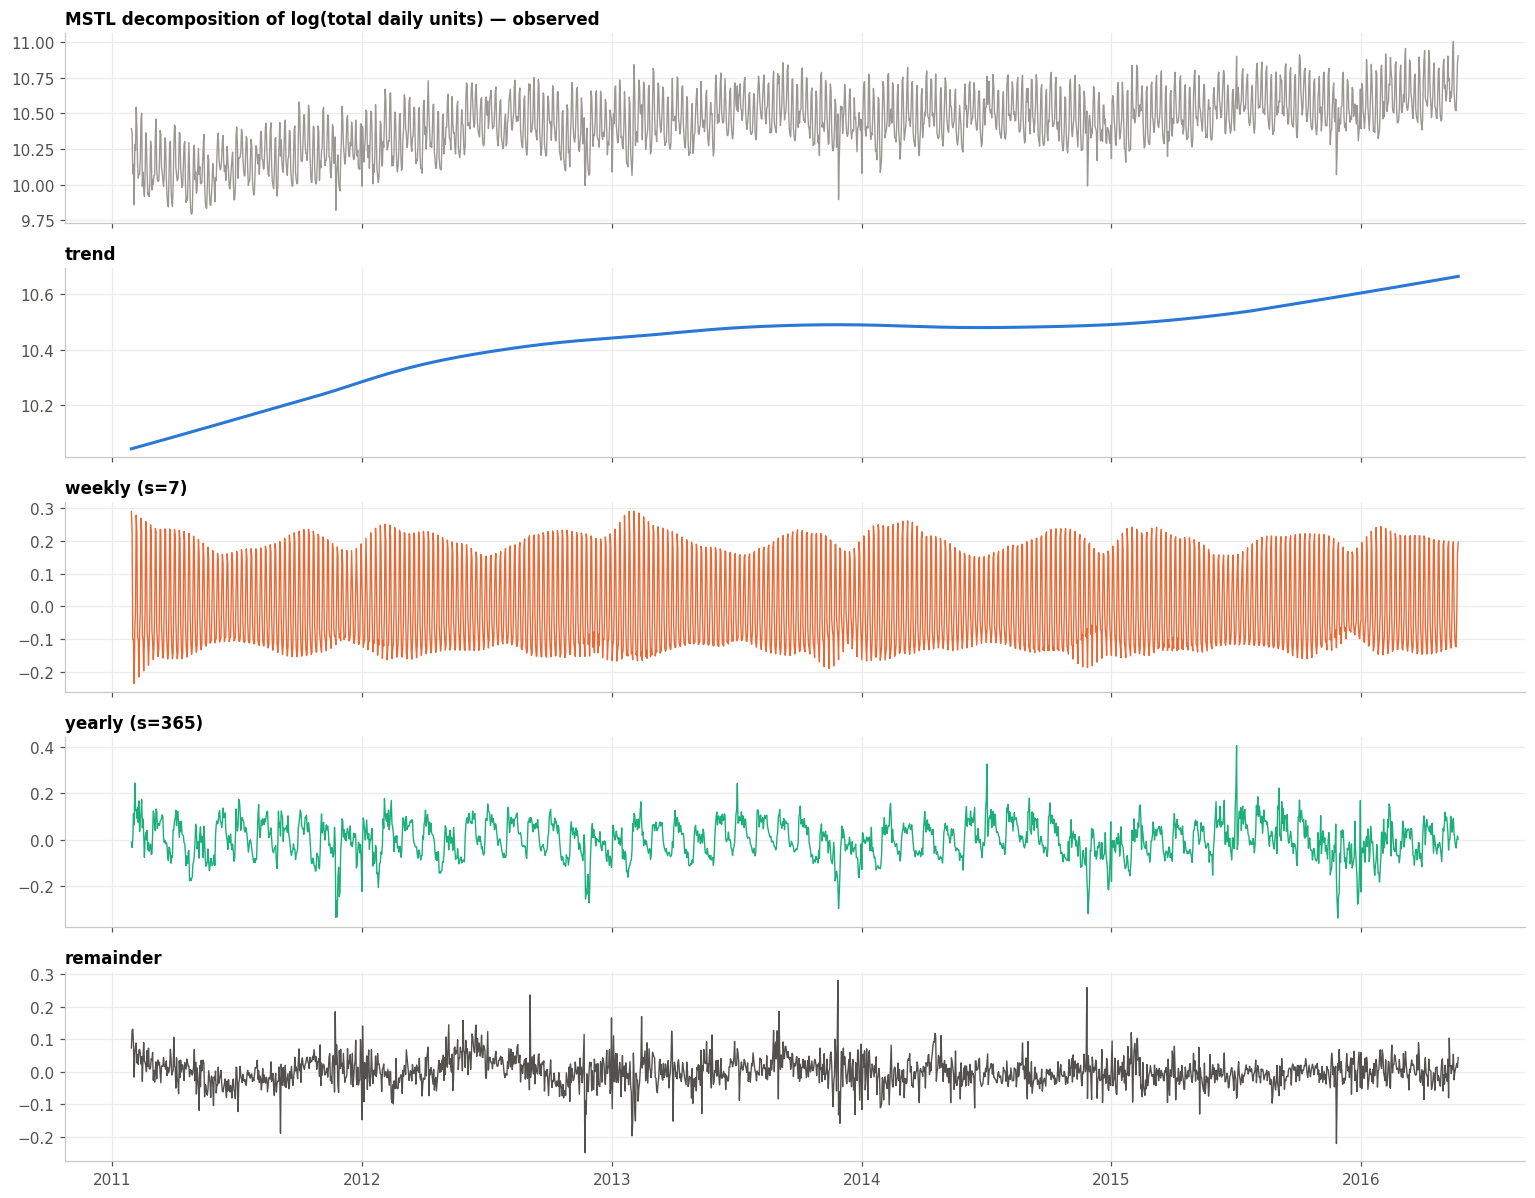

In [15]:
from statsmodels.tsa.seasonal import MSTL

# I decompose the LOG of sales: with a log, a pattern like "+20% on Saturday" becomes a constant shift,
# which is what an additive decomposition (trend + season + remainder) expects.
mstl_result = MSTL(np.log(ts_total_clean), periods=(7, 365)).fit()

df_mstl = pd.DataFrame({
    "observed (log)": mstl_result.observed,
    "trend": mstl_result.trend,
    "weekly (s=7)": mstl_result.seasonal["seasonal_7"],
    "yearly (s=365)": mstl_result.seasonal["seasonal_365"],
    "remainder": mstl_result.resid,
})

fig, axes = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
colors = [GREY, BLUE, ORANGE, AQUA, INK2]
for ax, col, color in zip(axes, df_mstl.columns, colors):
    ax.plot(df_mstl.index, df_mstl[col], color=color, lw=0.9 if col != "trend" else 2)
    ax.set_title(col, fontsize=11)
axes[0].set_title("MSTL decomposition of log(total daily units) — observed", fontsize=11)
plt.tight_layout(); plt.show()

In [16]:
# How much does each layer move the sales? I convert back from log to %:
# a component going from -0.1 to +0.1 means roughly -10% ... +10% around the trend.
tbl_component_size = pd.DataFrame({
    "typical swing (std, %)": (df_mstl[["weekly (s=7)", "yearly (s=365)", "remainder"]].std() * 100).round(1),
    "min (%)": (np.expm1(df_mstl[["weekly (s=7)", "yearly (s=365)", "remainder"]].min()) * 100).round(1),
    "max (%)": (np.expm1(df_mstl[["weekly (s=7)", "yearly (s=365)", "remainder"]].max()) * 100).round(1),
})
tbl_component_size

,"typical swing (std, %)",min (%),max (%)
weekly (s=7),13.3,-20.8,33.6
yearly (s=365),7.8,-28.8,50.2
remainder,4.4,-22.0,32.4


**read the 5 panels** (top to bottom): the observed series = trend + weekly + yearly + remainder.

- **Trend (blue):** fast growth in 2011–2012, flat in 2013–2014, growth again from 2015.
- **Weekly (orange):** the biggest moving part. Typical swing ±13 %, from about −21 % (midweek) to +34 % (weekend). Its size changes a little over time (it "breathes"), which is normal.
- **Yearly (green):** typical swing ±8 %, but very **wiggly**. With only ~5 years of history, the method has only 5 examples of each calendar day, so it also absorbs holidays (Thanksgiving, July 4, …) as if they were part of the yearly shape. The extreme min/max values in the table come from those holiday days.
- **Remainder (grey):** only ±4 % typical swing. Once trend and seasons are removed, there is not much left. This is the part ARIMA's AR and MA terms must explain.

**for ARIMA modeling:**
1. The **weekly** pattern is the #1 thing to capture → seasonal period `s = 7` in SARIMA.
2. The **yearly** pattern should be modelled **smoothly**  and the **holidays separately** (dummies). Otherwise the model learns holiday noise as if it were a seasonal pattern.
3. I used the **log** of sales because the weekly effect is a % effect (proportional), not a fixed number of units. ARIMA on log(sales) is a strong candidate to test

### Strength of trend and seasonality for every aggregate series

To compare *all* series in one table I asked claude and it gave me advice on using two scores from Hyndman & Athanasopoulos (*Forecasting: Principles and Practice*, ch. 4), both between 0 and 1:

- **Trend strength** = how much of the movement (once the season is removed) is slow trend rather than noise.
- **Weekly seasonal strength** = how much of the movement (once the trend is removed) is the weekly pattern rather than noise.

`F = max(0, 1 − Var(remainder) / Var(component + remainder))`. Close to 1 → strong and clean; close to 0 → drowned in noise. Here I use a simple STL with period 7 on each series (log scale, Christmas fixed).

In [17]:
from statsmodels.tsa.seasonal import STL

def strength_scores(ts):
    ts_log = np.log(fix_christmas(ts).clip(lower=1))
    stl = STL(ts_log, period=7, robust=True).fit()
    var_r = np.var(stl.resid)
    trend_strength = max(0, 1 - var_r / np.var(stl.trend + stl.resid))
    season_strength = max(0, 1 - var_r / np.var(stl.seasonal + stl.resid))
    return trend_strength, season_strength

rows = []
all_series = {"Total": ts_total}
all_series.update({f"State {c}": df_ts_state[c] for c in df_ts_state})
all_series.update({f"Cat {c}": df_ts_cat[c] for c in df_ts_cat})
all_series.update({f"Store {c}": df_ts_store[c] for c in df_ts_store})
all_series.update({f"Dept {c}": df_ts_dept[c] for c in df_ts_dept})

for name, ts in all_series.items():
    t, s = strength_scores(ts)
    rows.append({"series": name, "avg units/day": int(ts.mean()), "trend strength": round(t, 2), "weekly strength": round(s, 2)})

tbl_strength = pd.DataFrame(rows).set_index("series")
tbl_strength

,avg units/day,trend strength,weekly strength
series,,,
Total,34480,0.85,0.81
State CA,15042,0.83,0.83
State TX,9906,0.73,0.74
State WI,9532,0.83,0.63
Cat FOODS,23659,0.81,0.77
Cat HOBBIES,3215,0.77,0.66
Cat HOUSEHOLD,7606,0.92,0.82
Store CA_1,4035,0.76,0.83
Store CA_2,2997,0.83,0.84


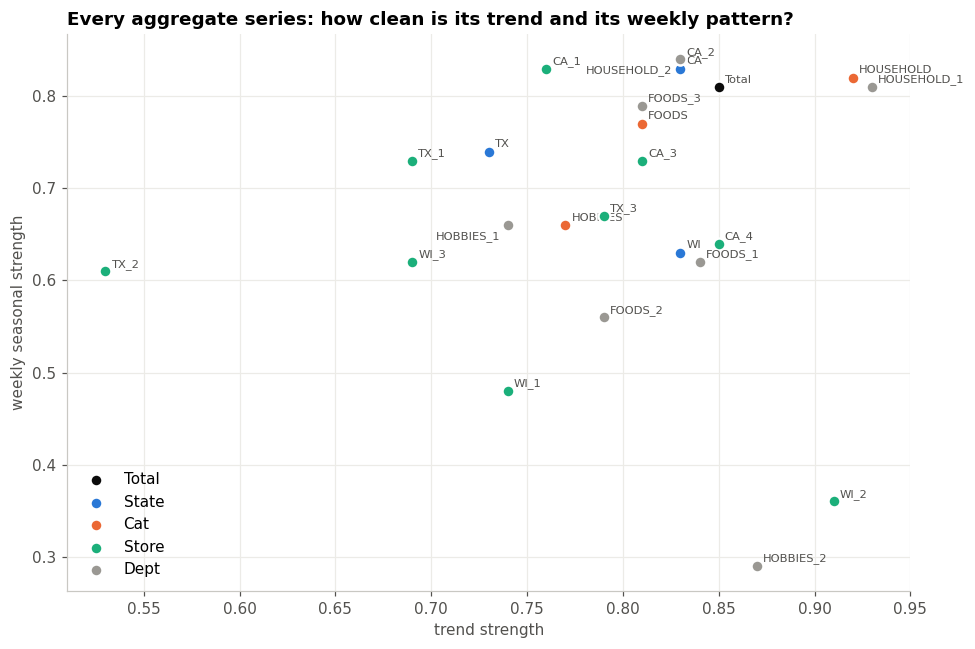

In [18]:
fig, ax = plt.subplots(figsize=(9, 6))
kind_color = {"Total": INK, "State": BLUE, "Cat": ORANGE, "Store": AQUA, "Dept": GREY}
for kind, color in kind_color.items():
    sub = tbl_strength[tbl_strength.index.str.startswith(kind)]
    ax.scatter(sub["trend strength"], sub["weekly strength"], s=60, color=color, label=kind,
               edgecolor="white", linewidth=1.5, zorder=3)
    for name, row in sub.iterrows():
        label = name.split(" ", 1)[-1]
        # two labels sit on top of their neighbours -> I push them to the left side
        if label in ["HOUSEHOLD_2", "HOBBIES_1"]:
            offset, align = (-5, -9), "right"
        else:
            offset, align = (4, 3), "left"
        ax.annotate(label, (row["trend strength"], row["weekly strength"]),
                    fontsize=7.5, color=INK2, xytext=offset, textcoords="offset points", ha=align)
ax.set_xlabel("trend strength"); ax.set_ylabel("weekly seasonal strength")
ax.set_title("Every aggregate series: how clean is its trend and its weekly pattern?")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**What I see**

- **Top-level series are clean:** Total (trend 0.85, weekly 0.81), CA, FOODS, HOUSEHOLD and FOODS_3 are all in the top-right corner. These are the **best candidates for SARIMA**.
- **Weak weekly pattern:** WI_2 (0.36), WI_1 (0.48) and HOBBIES_2 (0.29, which is also tiny at ~280 units/day). For these, the weekly pattern is partly drowned in noise or broken by the structural breaks seen in section 3.
- **TX_2** has the weakest trend (0.53): it goes up, then down.

**for ARIMA:**  **choose which series to model and what errors to expect**. I think it's better to focus on the total and the 3 states first, and treat stores as a second step. For WI stores I expect larger forecast errors.

## 6 · Calendar effects like holidays, events and SNAP

### 6.1 Events

**simple method:** for each event day, I compare its sales with a "normal" version of the same day = the average of the **same weekday one week before and one week after**. This automatically controls for the weekday effect and the trend.

`effect (%) = sales on event day / mean(sales 7 days before, sales 7 days after) − 1`

In [19]:
# Step 1: keep only the days that have an event AND have known sales
df_events = df_calendar.loc[df_calendar["event_name_1"].notna() & (df_calendar.index < len(d_cols)),
                            ["date", "event_name_1", "event_type_1"]].copy()

# Step 2: compute the effect for the total and for each category
def event_effect(ts, day):
    # Careful: the "normal" days must not be Christmas themselves!
    # e.g. New Year (1 Jan) -> 7 days before = 25 Dec = store closed -> the baseline would be way too low.
    # So the baseline comes from the Christmas-fixed version of the series.
    ts_baseline = fix_christmas(ts)
    before = ts_baseline.get(day - pd.Timedelta(days=7))
    after = ts_baseline.get(day + pd.Timedelta(days=7))
    if before is None or after is None:
        return np.nan
    return ts[day] / np.mean([before, after]) - 1

df_events["Total"] = [event_effect(ts_total, d) for d in df_events["date"]]
for cat in ["FOODS", "HOBBIES", "HOUSEHOLD"]:
    df_events[cat] = [event_effect(df_ts_cat[cat], d) for d in df_events["date"]]

# Step 3: average over the ~5 years for each event name
tbl_event_effect = (df_events.groupby(["event_name_1", "event_type_1"])[["Total", "FOODS", "HOBBIES", "HOUSEHOLD"]]
                    .mean().mul(100).round(1).sort_values("Total"))
print("Average effect of each event, in % vs a normal same-weekday (negative = fewer sales)")
tbl_event_effect

Average effect of each event, in % vs a normal same-weekday (negative = fewer sales)


,,Total,FOODS,HOBBIES,HOUSEHOLD
event_name_1,event_type_1,,,,
Christmas,National,-99.9,-99.9,-100.0,-100.0
Thanksgiving,National,-28.2,-21.0,-54.9,-38.1
NewYear,National,-18.0,-20.6,-19.9,-8.2
Mother's day,Cultural,-17.1,-15.2,-17.0,-23.1
Easter,Cultural,-12.0,-8.5,-20.0,-19.6
Father's day,Cultural,-10.7,-11.0,-4.3,-12.5
Halloween,Cultural,-8.4,-8.7,-2.2,-9.7
ValentinesDay,Cultural,-5.2,-2.3,-7.1,-13.5
Eid al-Fitr,Religious,-4.3,-5.6,-1.7,-0.6


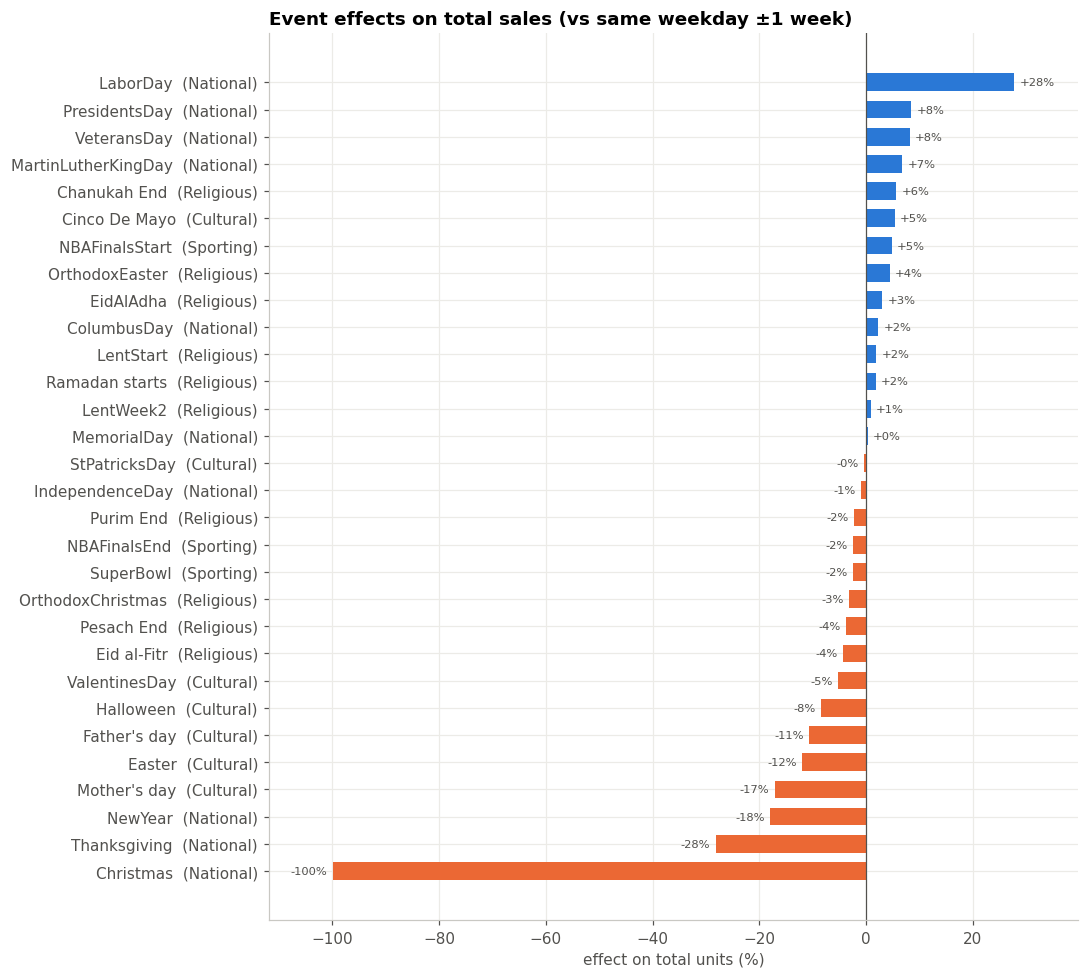

In [20]:
fig, ax = plt.subplots(figsize=(10, 9))
vals = tbl_event_effect["Total"]
labels = [f"{n}  ({t})" for n, t in vals.index]
colors = [ORANGE if v < 0 else BLUE for v in vals]
ax.barh(labels, vals, color=colors, height=0.65)
ax.axvline(0, color=INK2, lw=0.8)
for i, v in enumerate(vals):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right",
            fontsize=7.5, color=INK2)
ax.set_xlabel("effect on total units (%)")
ax.set_title("Event effects on total sales (vs same weekday ±1 week)")
ax.set_xlim(vals.min() - 12, vals.max() + 12)
plt.tight_layout(); plt.show()

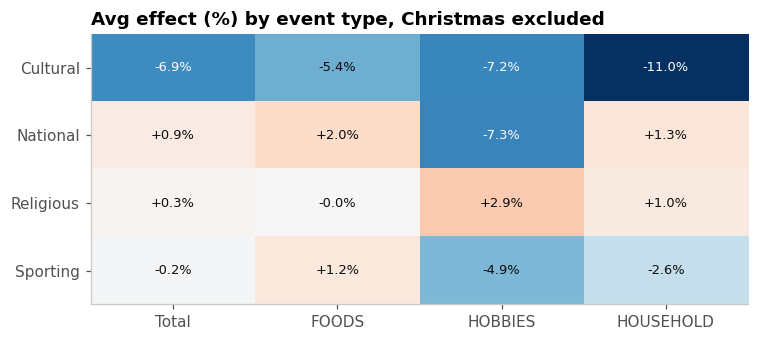

In [21]:
# Same thing summarised by event TYPE and category -> a small heatmap
tbl_event_type = df_events.groupby("event_type_1")[["Total", "FOODS", "HOBBIES", "HOUSEHOLD"]].mean().mul(100)
# I exclude Christmas here, because "store closed" is not a normal event effect and would dominate
no_xmas_events = df_events[df_events["event_name_1"] != "Christmas"]
tbl_event_type = no_xmas_events.groupby("event_type_1")[["Total", "FOODS", "HOBBIES", "HOUSEHOLD"]].mean().mul(100).round(1)

fig, ax = plt.subplots(figsize=(7, 3.2))
heatmap_table(tbl_event_type, "Avg effect (%) by event type, Christmas excluded", ax, center=0, fmt="{:+.1f}%")
plt.tight_layout(); plt.show()

**What I see** (after correcting the baseline so it never uses a closed Christmas day)

- **Big negative days:** Christmas (−100 %, closed), **Thanksgiving (−28 %**; HOBBIES −55 %), **New Year (−18 %)**, Mother's Day (−17 %), Easter (−12 %), Father's Day (−11 %).
- **Big positive day:** **Labor Day (+28 %**, all categories). Presidents', Veterans' and MLK Day are +7–8 %.
- **Most events are small:** 16 of the 30 events are within ±5 %, i.e. inside normal day-to-day noise.
- **The event type is a bad summary:** "National" averages ≈ +1 %, but it contains both Labor Day (+28 %) and Thanksgiving (−28 %), which cancel out.
- **Category matters:** HOBBIES and HOUSEHOLD react more to holidays than FOODS (e.g. Independence Day: FOODS +4 %, HOBBIES −17 %).

**Why it matters for ARIMA:** in SARIMAX I will **not** use 4 "event type" dummies. I'll use a few dummies for the **specific big events** (Thanksgiving, Christmas, New Year, Labor Day, Easter, Mother's Day…). Section 9 also shows that the **day before Thanksgiving** and **31 December** are big positive days, and they are **not** in `df_calendar` at all. I have to create those dummies???

## 7 · Prices and revenue (dollar sales)

So far everything is in **units**. But the M5 competition weights each series by its **dollar sales** in the last 28 days: an item that brings a lot of money counts more in the final score. So I want to know whether "big in units" = "big in dollars".

Prices are given **per week**, so I first sum units per week, then multiply by the weekly price.

In [24]:
# Step 1: which Walmart week does each day belong to?
week_of_day = df_calendar["wm_yr_wk"].iloc[:len(d_cols)].values

# Step 2: units per item x store x week  (transpose -> group the day rows by week -> transpose back)
df_units_weekly = df_sales_wide[d_cols].T
df_units_weekly.index = week_of_day
df_units_weekly = df_units_weekly.groupby(level=0).sum().T
df_units_weekly.insert(0, "store_id", df_sales_wide["store_id"])
df_units_weekly.insert(0, "item_id", df_sales_wide["item_id"])
df_units_weekly.insert(0, "cat_id", df_sales_wide["cat_id"])

# Step 3: long format (one row per item x store x week), then join the price of that week
df_units_weekly_long = df_units_weekly.melt(id_vars=["cat_id", "item_id", "store_id"],
                                            var_name="wm_yr_wk", value_name="units")
df_units_weekly_long["wm_yr_wk"] = df_units_weekly_long["wm_yr_wk"].astype("int16")
df_units_weekly_long = df_units_weekly_long.merge(
    df_prices.astype({"store_id": str, "item_id": str}), on=["store_id", "item_id", "wm_yr_wk"], how="left")
df_units_weekly_long["revenue"] = df_units_weekly_long["units"] * df_units_weekly_long["sell_price"]

print(df_units_weekly_long.shape)
print("Rows with units > 0 but no price (should be 0):",
      int(((df_units_weekly_long["units"] > 0) & df_units_weekly_long["sell_price"].isna()).sum()))
df_units_weekly_long.dropna().head()

(8476220, 7)
Rows with units > 0 but no price (should be 0): 0


,cat_id,item_id,store_id,wm_yr_wk,units,sell_price,revenue
7,HOBBIES,HOBBIES_1_008,CA_1,11101,37,0.46,17.020000
8,HOBBIES,HOBBIES_1_009,CA_1,11101,17,1.56,26.519999
9,HOBBIES,HOBBIES_1_010,CA_1,11101,1,3.17,3.170000
11,HOBBIES,HOBBIES_1_012,CA_1,11101,2,5.98,11.960000
14,HOBBIES,HOBBIES_1_015,CA_1,11101,9,0.70,6.300000


In [25]:
tbl_units_vs_dollars = df_units_weekly_long.groupby("cat_id")[["units", "revenue"]].sum()
tbl_units_vs_dollars["share of units (%)"] = (tbl_units_vs_dollars["units"] / tbl_units_vs_dollars["units"].sum() * 100).round(1)
tbl_units_vs_dollars["share of $ (%)"] = (tbl_units_vs_dollars["revenue"] / tbl_units_vs_dollars["revenue"].sum() * 100).round(1)
tbl_units_vs_dollars["avg $ per unit"] = (tbl_units_vs_dollars["revenue"] / tbl_units_vs_dollars["units"]).round(2)
tbl_units_vs_dollars[["share of units (%)", "share of $ (%)", "avg $ per unit"]]

,share of units (%),share of $ (%),avg $ per unit
cat_id,,,
FOODS,68.6,58.000000,2.42
HOBBIES,9.3,12.200000,3.74
HOUSEHOLD,22.1,29.799999,3.87


In [26]:
# How often do prices change? For each item x store I count how many different prices it had.
n_prices = df_prices.groupby(["store_id", "item_id"], observed=True)["sell_price"].nunique()
tbl_price_changes = n_prices.value_counts().sort_index()
tbl_price_changes = pd.DataFrame({"n item-stores": tbl_price_changes,
                                  "% of item-stores": (tbl_price_changes / tbl_price_changes.sum() * 100).round(1)})
tbl_price_changes.index.name = "number of distinct prices in 5 years"
print("Median number of distinct prices:", int(n_prices.median()))
tbl_price_changes.head(10)

Median number of distinct prices: 2


,n item-stores,% of item-stores
number of distinct prices in 5 years,,
1,8247,27.0
2,8396,27.5
3,6104,20.0
4,3575,11.7
5,1804,5.9
6,1006,3.3
7,534,1.8
8,368,1.2
9,140,0.5




- **Units ≠ dollars:** FOODS is 69 % of units but only **58 % of dollars** (cheap items, ~$2.4 per unit). HOUSEHOLD goes from 22 % of units to **30 % of dollars** (~$3.9 per unit).
- Because the M5 score weights series by **dollar sales**, HOUSEHOLD and HOBBIES count more in the final score than their unit volume suggests.
- **Prices are very sticky:** 27 % of item × store pairs **never** change price in 5 years, and the median is only 2 different prices.


## 8 · Intermittency : why single products are hard for ARIMA

In notebook 00 I saw 68 % zeros at item × store level. Here I classify every item × store series with the classic **Syntetos–Boylan** scheme. It uses two simple numbers:

- **ADI** (*Average Demand Interval*): on average, how many days between two sales? `ADI = number of days / number of days with sales`. ADI = 1 → sells every day; ADI = 5 → sells once every 5 days.
- **CV²** (*squared coefficient of variation*) of the non-zero sales: when it sells, does it sell a similar quantity each time (low) or very different quantities (high)?

| | CV² < 0.49 (stable quantities) | CV² ≥ 0.49 (variable quantities) |
|---|---|---|
| **ADI < 1.32** (sells almost every day) | **Smooth** — ARIMA OK | **Erratic** |
| **ADI ≥ 1.32** (many zero days) | **Intermittent** — Croston-type | **Lumpy** — hardest |

I only count days **after the first sale** (before that the product was not on the shelf, see notebook 00).

In [27]:
X = df_sales_wide[d_cols].to_numpy().astype("float32")
first_sale = (X > 0).argmax(axis=1)                                   # first day with a sale
on_shelf = np.arange(X.shape[1])[None, :] >= first_sale[:, None]       # True after launch

n_days = on_shelf.sum(axis=1)
n_sales_days = ((X > 0) & on_shelf).sum(axis=1)
adi = n_days / np.maximum(n_sales_days, 1)

X_nonzero = np.where((X > 0) & on_shelf, X, np.nan)
cv2 = (np.nanstd(X_nonzero, axis=1) / np.nanmean(X_nonzero, axis=1)) ** 2

df_intermittency = df_sales_wide[["id", "cat_id", "store_id"]].copy()
df_intermittency["ADI"] = adi
df_intermittency["CV2"] = cv2
df_intermittency["class"] = np.select(
    [(adi < 1.32) & (cv2 < 0.49), (adi < 1.32) & (cv2 >= 0.49), (adi >= 1.32) & (cv2 < 0.49)],
    ["Smooth", "Erratic", "Intermittent"], default="Lumpy")

tbl_intermittency = pd.crosstab(df_intermittency["cat_id"], df_intermittency["class"], normalize="index").mul(100).round(1)
tbl_intermittency.loc["ALL"] = (df_intermittency["class"].value_counts(normalize=True) * 100).round(1)
tbl_intermittency = tbl_intermittency[["Smooth", "Erratic", "Intermittent", "Lumpy"]]
print("% of item x store series in each demand class")
tbl_intermittency

% of item x store series in each demand class


class,Smooth,Erratic,Intermittent,Lumpy
cat_id,,,,
FOODS,8.3,4.5,60.6,26.6
HOBBIES,0.8,0.9,79.7,18.5
HOUSEHOLD,6.3,1.6,85.4,6.7
ALL,6.2,2.8,72.7,18.3


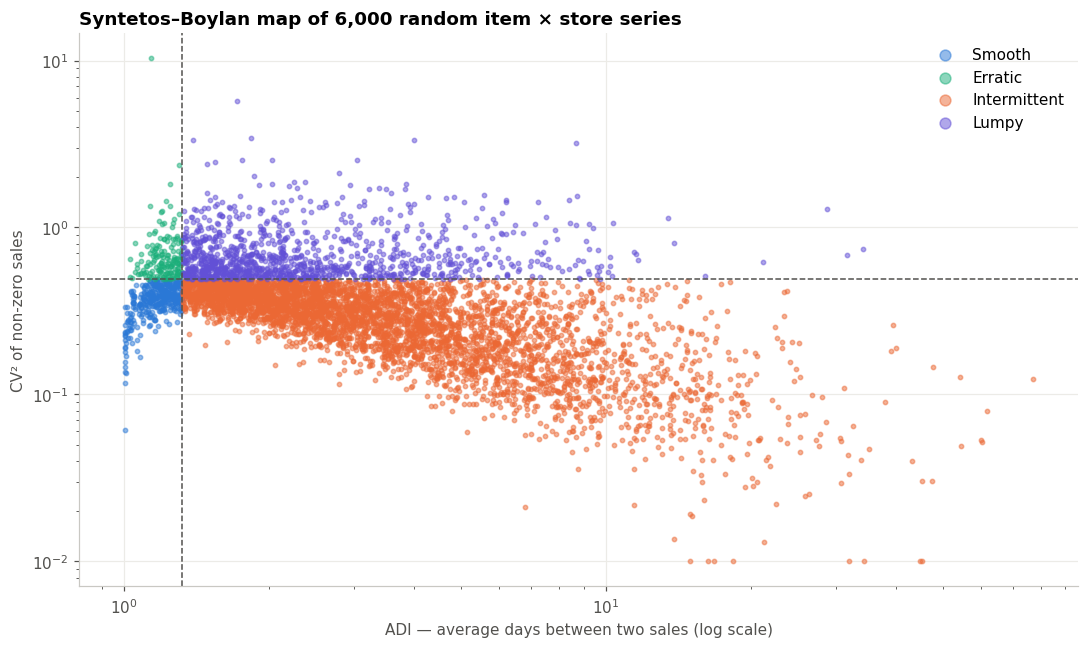

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
sample = df_intermittency.sample(6000, random_state=42)          # 6000 dots is enough to see the shape
class_color = {"Smooth": BLUE, "Erratic": AQUA, "Intermittent": ORANGE, "Lumpy": "#6250d6"}
for cls, color in class_color.items():
    sub = sample[sample["class"] == cls]
    # CV² can be exactly 0 (always sells 1 unit) -> log(0) is impossible, so I clip at 0.01 for the plot only
    ax.scatter(sub["ADI"], sub["CV2"].clip(lower=0.01), s=8, alpha=0.5, color=color, label=f"{cls}")
ax.axvline(1.32, color=INK2, lw=1, ls="--"); ax.axhline(0.49, color=INK2, lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ADI — average days between two sales (log scale)")
ax.set_ylabel("CV² of non-zero sales")
ax.set_title("Syntetos–Boylan map of 6,000 random item × store series")
ax.legend(loc="upper right", markerscale=2.5)
plt.tight_layout(); plt.show()

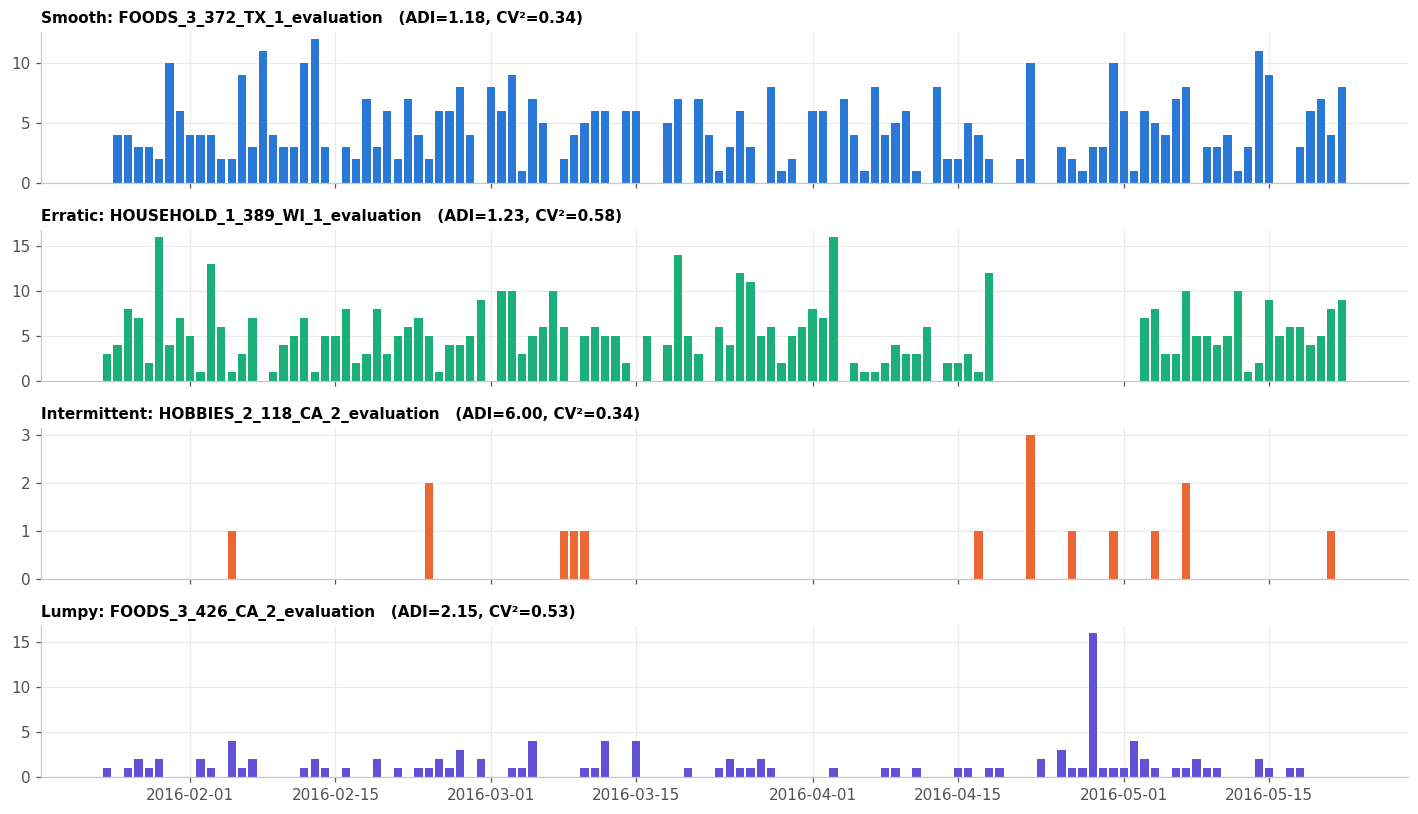

In [30]:
# To make it concrete: 4 random products, one per class, last 120 days
fig, axes = plt.subplots(4, 1, figsize=(13, 7.5), sharex=True)
for ax, cls in zip(axes, ["Smooth", "Erratic", "Intermittent", "Lumpy"]):
    row = df_intermittency[df_intermittency["class"] == cls].sample(1, random_state=1).index[0]
    y = X[row, -120:]
    ax.bar(sales_dates[-120:], y, color=class_color[cls], width=0.8)
    ax.set_title(f"{cls}: {df_sales_wide.loc[row, 'id']}   (ADI={adi[row]:.2f}, CV²={cv2[row]:.2f})", fontsize=10)
plt.tight_layout(); plt.show()

**What I see**

- Only **6 % of item × store series are "smooth"**, i.e. the kind of series ARIMA is designed for.
- **73 % are intermittent** (many zero days, stable quantity when sold) and **18 % are lumpy** (many zeros *and* very variable quantities).
- Even in FOODS, the most frequently sold category, only 8 % are smooth. HOUSEHOLD is 85 % intermittent.
- The **Erratic** example shows a long run of zeros in the middle of normal sales. That is most likely an **out-of-stock** period, another kind of "fake zero" (like the not-yet-launched zeros from notebook 00).

**Why it matters (the key argument of my part):** running ARIMA on each of the 30,490 items would mean using the wrong tool on ~94 % of them. Intermittent demand needs other methods (Croston, or ML with Poisson / Tweedie loss). This is the evidence-based reason why **our statistical part models aggregated series**, and why the ML part is needed for item-level forecasts. The two parts **complement** each other.

## 9 · Outliers and structural breaks

ARIMA assumes the "rules" of the series don't change in the middle. Two things break that:

- **Outliers** = single crazy days (Christmas, already handled; maybe other days).
- **Structural breaks** = the level suddenly jumps or drops and *stays* there (e.g. a store renovation, a new competitor).

To find suspicious days without guessing, I look at the **remainder** of the decomposition from section 5 (what is left once trend and seasons are removed) and flag days where it is very large (|robust z-score| > 4).

In [31]:
resid = df_mstl["remainder"]
# robust z-score: uses median and MAD instead of mean and std, so the outliers don't hide themselves
mad = np.median(np.abs(resid - resid.median()))
robust_z = (resid - resid.median()) / (1.4826 * mad)

tbl_outliers = pd.DataFrame({"units": ts_total, "robust z": robust_z.round(1),
                             "effect (%)": (np.expm1(resid) * 100).round(1)})
tbl_outliers = tbl_outliers.join(df_calendar.set_index("date")[["weekday", "event_name_1"]])
tbl_outliers = tbl_outliers[np.abs(tbl_outliers["robust z"]) > 4].sort_values("robust z")
print(f"{len(tbl_outliers)} unusual days out of {len(ts_total)}")
tbl_outliers

17 unusual days out of 1941


,units,robust z,effect (%),weekday,event_name_1
date,,,,,
2012-11-22,21909,-7.0,-22.0,Thursday,Thanksgiving
2015-11-26,23631,-6.2,-19.8,Thursday,Thanksgiving
2013-01-30,23523,-5.5,-17.9,Wednesday,NaN
2011-09-04,26925,-5.3,-17.2,Sunday,NaN
2013-11-30,31546,-4.5,-14.7,Saturday,NaN
2013-01-31,26751,-4.5,-14.7,Thursday,NaN
2013-02-04,28992,-4.3,-14.0,Monday,NaN
2013-03-31,34448,-4.3,-14.1,Sunday,Easter
2012-01-01,21807,-4.2,-13.7,Sunday,NewYear


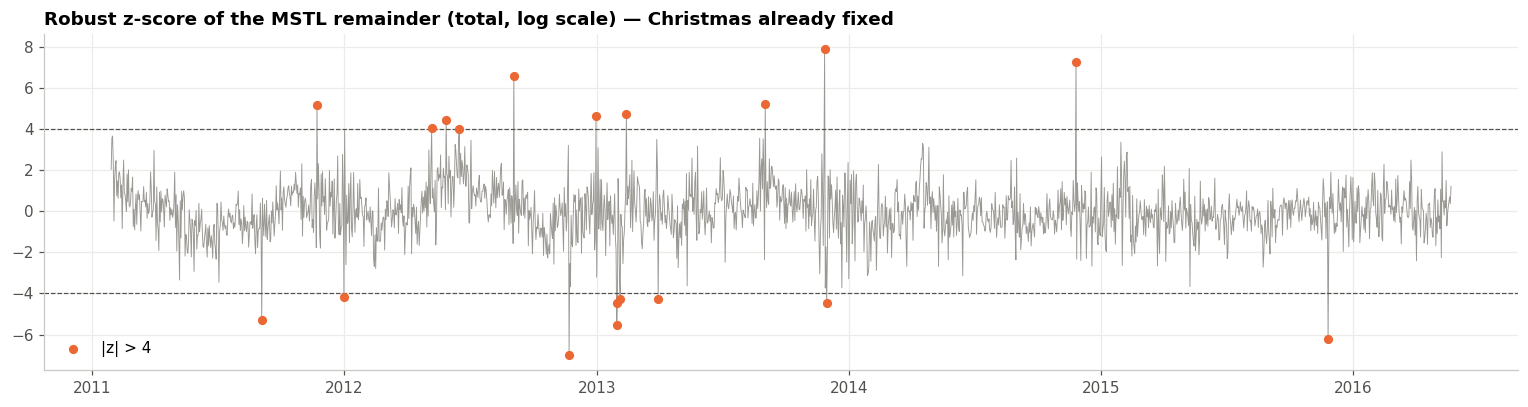

In [32]:
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(robust_z.index, robust_z, color=GREY, lw=0.6)
flag = np.abs(robust_z) > 4
ax.scatter(robust_z.index[flag], robust_z[flag], color=ORANGE, s=25, zorder=3, label="|z| > 4")
ax.axhline(4, color=INK2, lw=0.8, ls="--"); ax.axhline(-4, color=INK2, lw=0.8, ls="--")
ax.set_title("Robust z-score of the MSTL remainder (total, log scale) — Christmas already fixed")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

**What I see**: 17 unusual days (out of 1,941) once trend and seasons are removed.

| Pattern | Days | Effect |
|---|---|---|
| **Thanksgiving** | 2012, 2015 | about −20 % |
| **Wednesday before Thanksgiving** | 2011, 2013, 2014 | **+20 % to +32 %**, not in the calendar file! |
| **Labor Day** | 2012, 2013 | +20 % to +27 % |
| **31 December / 1 January** | 2012-12-31, 2012-01-01 | +18 % / −14 % |
| Other holidays | Memorial Day 2012, Easter 2013, Lent start 2013 | ±14 % to ±18 % |
| **Saturday after Thanksgiving** | 2013-11-30 | −15 % |
| **No event in the calendar** | 2013-01-30, 01-31, 02-04 (all stores), 2011-09-04 (mostly TX_2) | −14 % to −18 % |

The unexplained cluster in early 2013 hits **all 10 stores at once**, so it's not one store's problem. The dataset gives no reason (it could be weather, but I can't verify that from the data).

**Why it matters:** these days will show up as big residuals in ARIMA. The "eve" days are predictable, so they become dummies. The unexplained ones I keep in the data but flag, so they don't drive the parameter estimates (robust check in notebook 03).

### Store-level check

The total can hide problems of a single store (one store at zero = only −10 % on the total). So I also check each store against its own 15-day rolling median and flag days below 50 % of normal.

In [32]:
ratio_store = df_ts_store / df_ts_store.rolling(15, center=True, min_periods=5).median()
ratio_store = ratio_store[~is_christmas]                     # Christmas is already known

rows = []
for store in ratio_store.columns:
    bad_days = ratio_store.index[ratio_store[store] < 0.5]
    for day in bad_days:
        rows.append({"date": day.date(), "store": store, "units": df_ts_store.loc[day, store],
                     "% of normal": round(ratio_store.loc[day, store] * 100),
                     "event": df_calendar.set_index("date").loc[day, "event_name_1"]})
tbl_store_anomalies = pd.DataFrame(rows).sort_values("% of normal")
tbl_store_anomalies

,date,store,units,% of normal,event
3,2011-02-02,WI_1,2,0,NaN
2,2015-03-24,TX_2,131,4,NaN
5,2012-10-25,WI_1,318,26,NaN
1,2014-03-26,TX_2,1232,38,NaN
4,2011-11-24,WI_1,620,39,Thanksgiving
0,2013-11-28,CA_2,1172,42,Thanksgiving
9,2015-12-28,WI_1,1521,42,NaN
10,2011-11-24,WI_2,682,45,Thanksgiving
12,2014-11-27,WI_2,1616,45,Thanksgiving
6,2013-11-28,WI_1,1375,48,Thanksgiving


**What I see**

- **WI_1 on 2011-02-02: 2 units** (normally ~1,500). The store was basically closed that day.
- **TX_2 on 2015-03-24: 4 % of normal**, and TX_2 on 2014-03-26: 38 %. These are isolated "near-closure" days.
- **WI_1 on 2012-10-25: 26 %**, a few days before WI_1's big level jump (section 3). This fits a store-works / reopening story, but that's my guess, not something the data says.
- **Thanksgiving** hits the **Wisconsin stores** much harder (~45–50 % of normal) than CA/TX.

**Why it matters:** none of these is visible at the total level, but they would distort a store-level SARIMA. Before fitting stores, I'll replace them like Christmas (same weekday ±1 week).

## 10 · Summary from EDA findings to modelling decisions

| # | Finding | Evidence | for **ARIMA / SARIMA**  | for **ML / DL** |
|---|---|---|---|---|
| 1 | Item × store series are 94 % intermittent / lumpy | §8 | Model **aggregated** series only | Poisson / Tweedie loss; Croston as a baseline |
| 2 | Top-level series have strong, clean trend + weekly season | §5 strength table | Start with **Total + 3 states**; stores as a second step | — |
| 3 | Non-linear trend (growth → flat → growth) | §3, §5 | Use **differencing `d = 1`** (test with ADF/KPSS) | Rolling-window level features |
| 4 | Weekly pattern = biggest component (±13 %), proportional | §4, §5 | **`s = 7`**, model **log(sales)** | Day-of-week × state |
| 5 | Yearly pattern ±8 %, wiggly, state-specific | §4, §5 | **Fourier terms** as regressors, not `s = 365` | Month / day-of-year |
| 6 | A few big holidays + "eve" days not in the calendar | §6.1, §9 | **Specific event dummies** (Thanksgiving, its eve, Christmas, NYE / New Year, Labor Day, Easter, Mother's Day) | Same dummies; add "day before" features |
| 7 | Structural breaks in WI_1, WI_2, CA_2 | §3 | Fit stores on post-break data or add step dummies | Same awareness |
| 8 | Christmas closure + store-level outage days | §4, §9 | **Replace** (same weekday ±1 week) before fitting | Drop or flag |
| 9 | Prices sticky; dollars ≠ units | §7 | Prices not used at aggregate level | Price features matter for them; the M5 metric weights by $ |
| 10 | Last 28 days are known | notebook 00 | **Test set = 2016-04-25 → 2016-05-22**, horizon h = 28 | Same split → comparable scores |


In [33]:
# Export the aggregate series + calendar columns for notebook 02 / 03 (and for the ML teammates).
# Wide format: one row per date, one column per series -> easy to read in Excel too.
df_export = pd.DataFrame({"total": ts_total})
df_export = df_export.join(df_ts_state.add_prefix("state_"))
df_export = df_export.join(df_ts_cat.add_prefix("cat_"))
df_export = df_export.join(df_ts_store.add_prefix("store_"))
df_export = df_export.join(df_ts_dept.add_prefix("dept_"))
df_export = df_export.join(df_ts_state_cat.add_prefix("statecat_"))

calendar_cols = ["d", "wm_yr_wk", "weekday", "event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI"]
df_export = df_calendar.set_index("date")[calendar_cols].join(df_export, how="inner")
df_export["is_christmas"] = is_christmas.astype(int)
df_export["is_test"] = (df_export.index >= TEST_START).astype(int)

df_export.to_csv(OUT_DIR / "m5_daily_aggregates.csv")
print("Saved:", OUT_DIR / "m5_daily_aggregates.csv", df_export.shape)
df_export.iloc[:3, :14]

Saved: data_processed/m5_daily_aggregates.csv (1941, 43)


,d,wm_yr_wk,weekday,event_name_1,event_type_1,snap_CA,snap_TX,snap_WI,total,state_CA,state_TX,state_WI,cat_FOODS,cat_HOBBIES
date,,,,,,,,,,,,,,
2011-01-29,d_1,11101,Saturday,NaN,NaN,0,0,0,32631,14195,9438,8998,23178,3764
2011-01-30,d_2,11101,Sunday,NaN,NaN,0,0,0,31749,13805,9630,8314,22758,3357
2011-01-31,d_3,11101,Monday,NaN,NaN,0,0,0,23783,10108,6778,6897,17174,2682
